# Класифікація тяжкості ДТП — OneVsRest(LinearSVC) і OneVsRest(FMClassifier)

Ціль: `label = Severity - 1` (класи 0–3). Дані з `classification_data_preparation.ipynb`.

Для `LinearSVC` немає ймовірностей — ROC-AUC обчислюється за неперервними margin-score. Для `FMClassifier` — за score позитивного класу. Пороги оптимізуються як зсуви до чотирьох One-vs-Rest score на validation без використання test.

## Етап 0. Середовище й налаштування

In [4]:
import os, sys, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Estimator
from pyspark.ml.evaluation import Evaluator
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import OneVsRest, LinearSVC, FMClassifier
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.functions import vector_to_array
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.param.shared import Param, Params
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score, classification_report

ROOT = Path.cwd() if (Path.cwd() / 'main.py').exists() else Path.cwd().parent
DATA = ROOT / 'data' / 'processed' / 'classification'
OUT = ROOT / 'data' / 'models'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
TUNE_ROWS = int(os.getenv('TUNE_ROWS','50000'))  # встановити 80000-100000 якщо вистачає ресурсів
TRAIN_FRACTION = float(os.getenv('TRAIN_FRACTION','1'))
SHAP_ROWS = int(os.getenv('SHAP_ROWS','2000'))
CV_FOLDS = 5
CLASSES = [0,1,2,3]
assert (DATA/'metadata.json').exists(), 'Спочатку завершіть classification_data_preparation.ipynb'
os.environ['PYSPARK_PYTHON']=sys.executable
spark = (SparkSession.builder
         .appName('US-Accidents-classification-yh')
         .master('local[2]')
         .config('spark.driver.memory', '8g')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.driver.maxResultSize', '2g')
         .config('spark.ui.showConsoleProgress', 'false')
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print('Spark:',spark.version)

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark: 4.2.1


## Етап 1. Train / valid / test: завантаження, структура, баланс класів

In [5]:
meta = json.loads((DATA/'metadata.json').read_text(encoding='utf-8'))
FEATURES = meta['feature_names']
SAFE = [f'f{i}' for i in range(len(FEATURES))]
def read_split(split):
    src = spark.read.parquet(str(DATA/split))
    cols = [F.col('`'+c.replace('`','``')+'`').cast('double').alias(s)
            for c,s in zip(FEATURES,SAFE)]
    return src.select('ID',F.col('label').cast('double').alias('label'), *cols)
raw={s:read_split(s) for s in ('train','valid','test')}
if TRAIN_FRACTION < 1:
    raw['train']=raw['train'].sampleBy('label',{float(k):TRAIN_FRACTION for k in CLASSES},SEED)
for s,d in raw.items():
    print(s, 'columns:',len(d.columns))
    display(d.select('label',*SAFE[:3]).limit(4).toPandas())

train columns: 246


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,f0,f1,f2
0,1.0,-0.368475,-1.365461,-0.579527
1,2.0,0.538872,0.020882,-0.579527
2,1.0,1.124514,0.419365,-0.579527
3,1.0,-0.014757,0.467713,-0.579527


valid columns: 246


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,f0,f1,f2
0,1.0,-0.240925,0.786081,-0.579527
1,1.0,-0.395562,0.871742,-0.579527
2,2.0,-0.410095,-1.349743,-0.579527
3,1.0,-1.198378,-0.161123,-0.579527


test columns: 246


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,f0,f1,f2
0,1.0,-0.082479,0.940955,-0.579527
1,2.0,0.502197,0.289976,-0.579527
2,1.0,-0.441262,-1.332127,-0.579527
3,1.0,0.276899,1.000688,-0.579527


In [6]:
assembler=VectorAssembler(inputCols=SAFE,outputCol='features',handleInvalid='error')
data={s:assembler.transform(df).select('ID','label','features') for s,df in raw.items()}
counts={s:data[s].count() for s in data}
class_dist = {s:{int(r['label']):int(r['count']) for r in d.groupBy('label').count().collect()} for s,d in data.items()}
display(pd.DataFrame(class_dist).fillna(0).astype(int))
weights={float(k):sum(class_dist['train'].values())/(4*max(1,class_dist['train'].get(k,0))) for k in CLASSES}
weight_map=F.create_map(*[x for k,v in weights.items() for x in (F.lit(k),F.lit(float(v)))])
data['train']=data['train'].withColumn('weight',weight_map[F.col('label')].cast('double'))
print('Розміри:',counts,'Ваги:',weights)

,train,valid,test
1,3758419,536450,1073109
0,42475,6015,12064
3,124058,17649,35042
2,864430,123763,246235


Розміри: {'train': 4789382, 'valid': 683877, 'test': 1366450} Ваги: {0.0: 28.189417304296644, 1.0: 0.31857690693879526, 2.0: 1.385127193642053, 3.0: 9.65149768656596}


## Етап 2. Стратифікована вибірка 50–100 тис. та 5-fold CV (macro-F1)

In [7]:
frac = min(1.0, TUNE_ROWS/max(1,counts['train']))
w = Window.partitionBy('label').orderBy(F.rand(SEED))
tune=(data['train'].sampleBy('label',{float(k):frac for k in CLASSES},SEED)
      .withColumn('fold',((F.row_number().over(w)-1)%CV_FOLDS).cast('int'))
      .persist(StorageLevel.MEMORY_AND_DISK))
print('CV rows:',tune.count())

class MacroF1Evaluator(Evaluator):
    def _evaluate(self,pred):
        m=np.zeros((4,4),dtype=float)
        for r in pred.groupBy('label','prediction').count().collect():
            y,p=int(r['label']),int(r['prediction'])
            if y in CLASSES and p in CLASSES:m[y,p]+=r['count']
        tp=np.diag(m); p=m.sum(axis=0); r=m.sum(axis=1)
        den=p+r
        return float(np.mean(np.divide(2*tp,den,out=np.zeros_like(tp),where=den>0)))
    def isLargerBetter(self): return True

evaluator = MacroF1Evaluator()
svm=OneVsRest(classifier=LinearSVC(featuresCol='features',labelCol='label',maxIter=30,regParam=.1),
              featuresCol='features',labelCol='label',predictionCol='prediction')
fm=OneVsRest(classifier=FMClassifier(featuresCol='features',labelCol='label',maxIter=30,
                                  factorSize=4,regParam=.1,seed=SEED),
             featuresCol='features',labelCol='label',predictionCol='prediction')
FAMILIES={'OVR LinearSVC':svm,'OVR FMClassifier':fm}
GRIDS={
  'OVR LinearSVC':(ParamGridBuilder().addGrid(svm.getClassifier().regParam,[.01,.1])
                   .addGrid(svm.getClassifier().maxIter,[30]).build()),
  'OVR FMClassifier':(ParamGridBuilder().addGrid(fm.getClassifier().factorSize,[4,8])
                      .addGrid(fm.getClassifier().regParam,[.01,.1])
                      .addGrid(fm.getClassifier().maxIter,[30]).build())}

CV rows: 50248


In [8]:
BEST={}; CV_RESULTS={}
for fam,est in FAMILIES.items():
    print('CV:',fam,flush=True)
    cv=CrossValidator(estimator=est,estimatorParamMaps=GRIDS[fam],evaluator=evaluator,
                      numFolds=CV_FOLDS,foldCol='fold',parallelism=1,seed=SEED)
    fit=cv.fit(tune)
    best_idx=int(np.argmax(fit.avgMetrics))
    BEST[fam]=GRIDS[fam][best_idx]
    t=pd.DataFrame([{p.name:v for p,v in pm.items()} for pm in GRIDS[fam]])
    t['CV macro F1']=fit.avgMetrics
    CV_RESULTS[fam]=t.sort_values('CV macro F1',ascending=False)
    display(CV_RESULTS[fam])

CV: OVR LinearSVC


,regParam,maxIter,CV macro F1
0,0.01,30,0.422820
1,0.10,30,0.413498


CV: OVR FMClassifier


,factorSize,regParam,maxIter,CV macro F1
1,4,0.10,30,0.537974
3,8,0.10,30,0.529068
2,8,0.01,30,0.525142
0,4,0.01,30,0.519032


## Етап 3. Base / tuned, weighted / unweighted на train

In [11]:
def cm_and_metrics(pred):
    cm = np.zeros((4, 4), dtype=np.int64)

    for r in pred.groupBy('label', 'prediction').count().collect():
        cm[int(r['label']), int(r['prediction'])] = int(r['count'])

    tp = np.diag(cm).astype(float)
    support = cm.sum(axis=1)
    pred_counts = cm.sum(axis=0)

    precision = np.divide(
        tp, pred_counts, out=np.zeros(4), where=pred_counts > 0
    )
    recall = np.divide(
        tp, support, out=np.zeros(4), where=support > 0
    )
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(4),
        where=(precision + recall) > 0
    )

    return {
        'accuracy': round(float(tp.sum() / max(1, cm.sum())), 5),
        'macro F1': round(float(f1.mean()), 5),
        'weighted F1': round(
            float(np.average(f1, weights=support)), 5
        )
    }, cm


class_counts = {
    int(r['label']): int(r['count'])
    for r in data['train'].groupBy('label').count().collect()
}

total = sum(class_counts.values())
n_classes = len(class_counts)

weight_expr = F.lit(1.0)

for cls, count in class_counts.items():
    weight_expr = F.when(
        F.col('label') == cls,
        F.lit(float(total / (n_classes * count)))
    ).otherwise(weight_expr)

data['train'] = data['train'].withColumn('weight', weight_expr)

print("Ваги класів:", {
    cls: round(total / (n_classes * count), 4)
    for cls, count in class_counts.items()
})


MODELS = {}
TIMES = {}
TRAIN_METRICS = {}

for fam, est in FAMILIES.items():
    for variant, params in [('base', {}), ('tuned', BEST[fam])]:
        for weighted in (False, True):

            name = f'{fam} {variant} ' + (
                'weighted' if weighted else 'unweighted'
            )

            clf = est.getClassifier().copy(params)

            if weighted:
                clf.setWeightCol('weight')
            elif clf.isSet(clf.weightCol):
                clf.clear(clf.weightCol)

            model = OneVsRest(
                classifier=clf,
                featuresCol='features',
                labelCol='label',
                predictionCol='prediction'
            )

            if weighted:
                model.setWeightCol('weight')

            print("Fit:", name, flush=True)
            t0 = time.time()

            MODELS[name] = model.fit(data['train'])
            TIMES[name] = round(time.time() - t0, 1)

            TRAIN_METRICS[name] = cm_and_metrics(
                MODELS[name].transform(data['train'])
            )[0]

            print("Готово:", name, "|", TIMES[name], "с", flush=True)


train_table = pd.DataFrame.from_dict(
    TRAIN_METRICS, orient='index'
)
train_table['seconds'] = pd.Series(TIMES)

display(train_table.sort_values('macro F1', ascending=False))


Ваги класів: {1: 0.3186, 0: 28.1894, 3: 9.6515, 2: 1.3851}
Fit: OVR LinearSVC base unweighted
Готово: OVR LinearSVC base unweighted | 540.7 с
Fit: OVR LinearSVC base weighted
Готово: OVR LinearSVC base weighted | 540.1 с
Fit: OVR LinearSVC tuned unweighted
Готово: OVR LinearSVC tuned unweighted | 547.0 с
Fit: OVR LinearSVC tuned weighted
Готово: OVR LinearSVC tuned weighted | 554.2 с
Fit: OVR FMClassifier base unweighted
Готово: OVR FMClassifier base unweighted | 4339.7 с


AttributeError: 'FMClassifier' object has no attribute 'setWeightCol'

In [12]:

pd.DataFrame.from_dict(
    TRAIN_METRICS, orient='index'
).to_csv(OUT / 'classification_train_metrics_progress.csv')

for fam, est in FAMILIES.items():
    if 'FMClassifier' not in fam:
        continue

    for variant, params in [('base', {}), ('tuned', BEST[fam])]:
        for weighted in (False, True):

            name = f'{fam} {variant} ' + (
                'weighted' if weighted else 'unweighted'
            )

            # Уже навчена модель залишається в MODELS
            if name in MODELS:
                print('Уже готово:', name, flush=True)
                continue

            clf = est.getClassifier().copy(params)

            if weighted:
                clf.set(clf.weightCol, 'weight')
            elif clf.isSet(clf.weightCol):
                clf.clear(clf.weightCol)

            model = OneVsRest(
                classifier=clf,
                featuresCol='features',
                labelCol='label',
                predictionCol='prediction'
            )

            if weighted:
                model.setWeightCol('weight')

            print('Fit:', name, flush=True)
            t0 = time.time()

            trained = model.fit(data['train'])
            MODELS[name] = trained
            TIMES[name] = round(time.time() - t0, 1)

            TRAIN_METRICS[name] = cm_and_metrics(
                trained.transform(data['train'])
            )[0]

            pd.DataFrame.from_dict(
                TRAIN_METRICS, orient='index'
            ).to_csv(OUT / 'classification_train_metrics_progress.csv')

            print('Готово:', name, '|', TIMES[name], 'с', flush=True)

train_table = pd.DataFrame.from_dict(
    TRAIN_METRICS, orient='index'
)
train_table['seconds'] = pd.Series(TIMES)

display(train_table.sort_values('macro F1', ascending=False))


Уже готово: OVR FMClassifier base unweighted
Fit: OVR FMClassifier base weighted
Готово: OVR FMClassifier base weighted | 4297.5 с
Fit: OVR FMClassifier tuned unweighted
Готово: OVR FMClassifier tuned unweighted | 4204.3 с
Fit: OVR FMClassifier tuned weighted
Готово: OVR FMClassifier tuned weighted | 4205.8 с


,accuracy,macro F1,weighted F1,seconds
OVR FMClassifier tuned weighted,0.86894,0.54121,0.86222,4205.8
OVR FMClassifier tuned unweighted,0.86894,0.54121,0.86222,4204.3
OVR FMClassifier base weighted,0.86894,0.54121,0.86222,4297.5
OVR FMClassifier base unweighted,0.86894,0.54121,0.86222,4339.7
OVR LinearSVC tuned weighted,0.72885,0.50550,0.78420,554.2
OVR LinearSVC base weighted,0.69465,0.47698,0.75261,540.1
OVR LinearSVC tuned unweighted,0.88646,0.42552,0.86907,547.0
OVR LinearSVC base unweighted,0.88038,0.41664,0.86138,540.7


## Етап 4. Validation, вибір лідерів і оптимізація score-offset

In [13]:
VALID_METRICS={}
for name,model in MODELS.items():
    VALID_METRICS[name]=cm_and_metrics(model.transform(data['valid']))[0]
valid_table=pd.DataFrame.from_dict(VALID_METRICS,orient='index')
display(valid_table.sort_values('macro F1',ascending=False))
LEADERS={fam:max((n for n in MODELS if n.startswith(fam+' ')),
                 key=lambda n:VALID_METRICS[n]['macro F1']) for fam in FAMILIES}
print('Лідери:',LEADERS)

def scored_frame(model,frame):
    out=frame
    is_svm=isinstance(model.models[0],type(MODELS[LEADERS['OVR LinearSVC']].models[0]))
    for k,binary_model in enumerate(model.models):
        tmp=binary_model.transform(out)
        src='rawPrediction' if is_svm else 'probability'
        out=tmp.withColumn(f's{k}',vector_to_array(F.col(src))[1].cast('double'))
        # Вичистити проміжні колонки, щоб не конфліктували в наступній бінарній моделі
        for c in ('rawPrediction','probability','prediction'):
            if c in out.columns:out=out.drop(c)
    return out

def score_sample(model,split,n=12000):
    frame=data[split].sample(False,min(1.,n/max(1,counts[split])),SEED).limit(n)
    return scored_frame(model,frame).select('label',*[f's{k}' for k in CLASSES]).toPandas()

SAMPLES={}; OFFSETS={}; THRESHOLD_F1={}
for fam,name in LEADERS.items():
    smp=score_sample(MODELS[name],'valid')
    y=smp.label.astype(int).to_numpy(); scores=smp[[f's{k}' for k in CLASSES]].to_numpy()
    scale=max(1e-8,float(np.std(scores)))
    offsets=np.zeros(4)
    best=f1_score(y,np.argmax(scores+offsets,axis=1),average='macro',labels=CLASSES,zero_division=0)
    for sweep in range(3):
        for k in CLASSES:
            candidate=offsets.copy()
            for shift in np.linspace(-.6,.6,13)*scale:
                candidate[k]=offsets[k]+shift
                val=f1_score(y,np.argmax(scores+candidate,axis=1),average='macro',labels=CLASSES,zero_division=0)
                if val>best:best=val; offsets=candidate.copy()
    SAMPLES[fam]=smp; OFFSETS[fam]=offsets; THRESHOLD_F1[fam]=best
    print(fam,'val sampled macro F1:',round(best,5),'offset:',offsets)

,accuracy,macro F1,weighted F1
OVR FMClassifier tuned weighted,0.86988,0.54340,0.86341
OVR FMClassifier tuned unweighted,0.86988,0.54340,0.86341
OVR FMClassifier base weighted,0.86988,0.54340,0.86341
OVR FMClassifier base unweighted,0.86988,0.54340,0.86341
OVR LinearSVC tuned weighted,0.72883,0.50518,0.78435
OVR LinearSVC base weighted,0.69513,0.47706,0.75327
OVR LinearSVC tuned unweighted,0.88706,0.42645,0.86988
OVR LinearSVC base unweighted,0.88108,0.41752,0.86231


Лідери: {'OVR LinearSVC': 'OVR LinearSVC tuned weighted', 'OVR FMClassifier': 'OVR FMClassifier base unweighted'}


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


OVR LinearSVC val sampled macro F1: 0.60962 offset: [-2.48438654  0.         -0.46582248 -2.6396607 ]


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


OVR FMClassifier val sampled macro F1: 0.55853 offset: [ 0.         -0.63827167  0.          0.        ]


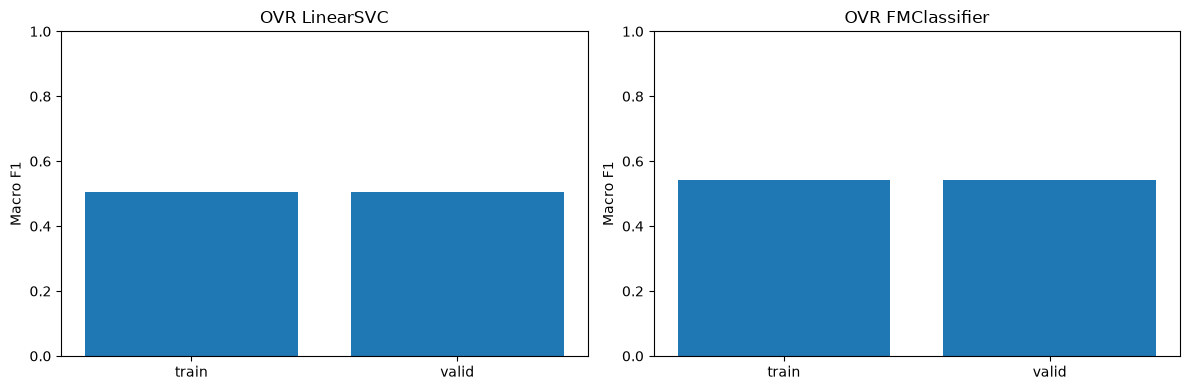

In [14]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for j,(fam,name) in enumerate(LEADERS.items()):
    axes[j].bar(['train','valid'],[TRAIN_METRICS[name]['macro F1'],VALID_METRICS[name]['macro F1']])
    axes[j].set_ylim(0,1);axes[j].set_title(fam);axes[j].set_ylabel('Macro F1')
plt.tight_layout();plt.show()

## Етап 5. Test: лідери, матриці помилок, ROC-AUC One-vs-Rest

In [15]:

TEST={}; TEST_CM={}; TEST_SCORE={}; TEST_AUC={}
for fam,name in LEADERS.items():
    model=MODELS[name]
    ds=scored_frame(model,data['test'])
    arr=F.array(*[(F.col(f's{k}')+F.lit(float(OFFSETS[fam][k]))) for k in CLASSES])
    p=(ds.withColumn('_scores',arr)
       .withColumn('prediction',(F.array_position(F.col('_scores'),F.array_max(F.col('_scores')))-1).cast('double')))
    TEST[fam],TEST_CM[fam]=cm_and_metrics(p)
    s=p.sample(False,min(1.,25000/max(1,counts['test'])),SEED).limit(25000)
    small=s.select('label',*[f's{k}' for k in CLASSES]).toPandas()
    yt=small.label.astype(int).to_numpy()
    st=small[[f's{k}' for k in CLASSES]].to_numpy()
    aucs={f'class {k+1}':roc_auc_score((yt==k).astype(int),st[:,k]) if 0<(yt==k).sum()<len(yt) else np.nan
          for k in CLASSES}
    TEST_AUC[fam]=aucs;TEST_SCORE[fam]=(yt,st)
    TEST[fam]['macro ROC-AUC (sample)']=float(np.nanmean(list(aucs.values())))
display(pd.DataFrame.from_dict(TEST,orient='index'))

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recomm

,accuracy,macro F1,weighted F1,macro ROC-AUC (sample)
OVR LinearSVC,0.84581,0.60892,0.85317,0.915744
OVR FMClassifier,0.81734,0.55288,0.82750,0.864219


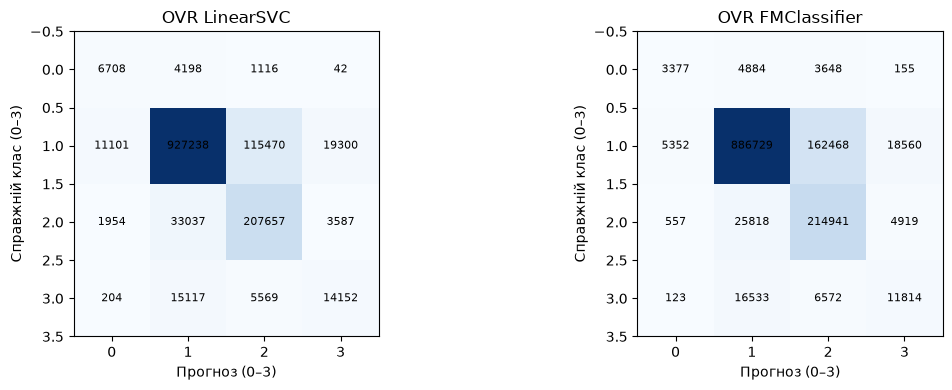

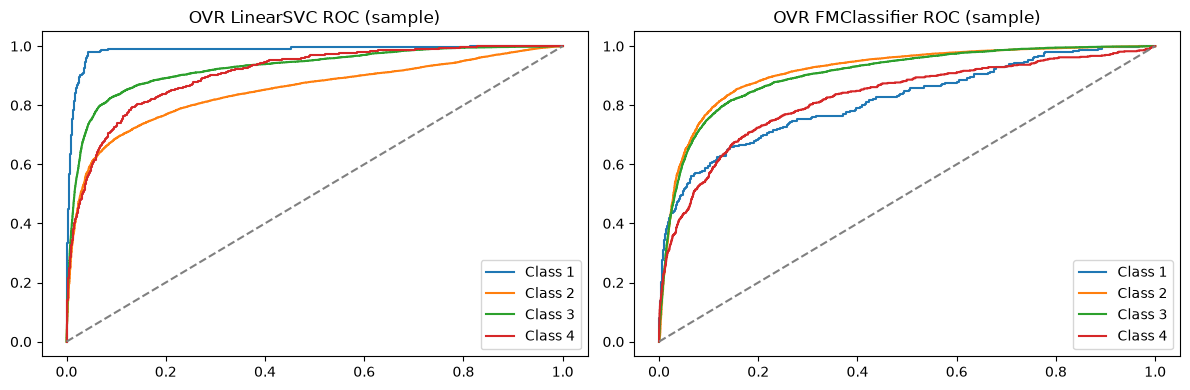

In [16]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(fam,cm) in zip(axes,TEST_CM.items()):
    im=ax.imshow(cm,cmap='Blues')
    ax.set_title(fam);ax.set_xlabel('Прогноз (0–3)');ax.set_ylabel('Справжній клас (0–3)')
    for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',fontsize=8)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(fam,(y,s)) in zip(axes,TEST_SCORE.items()):
    for k in CLASSES:
        fpr,tpr,_=roc_curve((y==k).astype(int),s[:,k]);ax.plot(fpr,tpr,label=f'Class {k+1}')
    ax.plot([0,1],[0,1],'--',color='gray');ax.legend();ax.set_title(fam+' ROC (sample)')
plt.tight_layout();plt.show()

## Етап 6. SHAP 

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


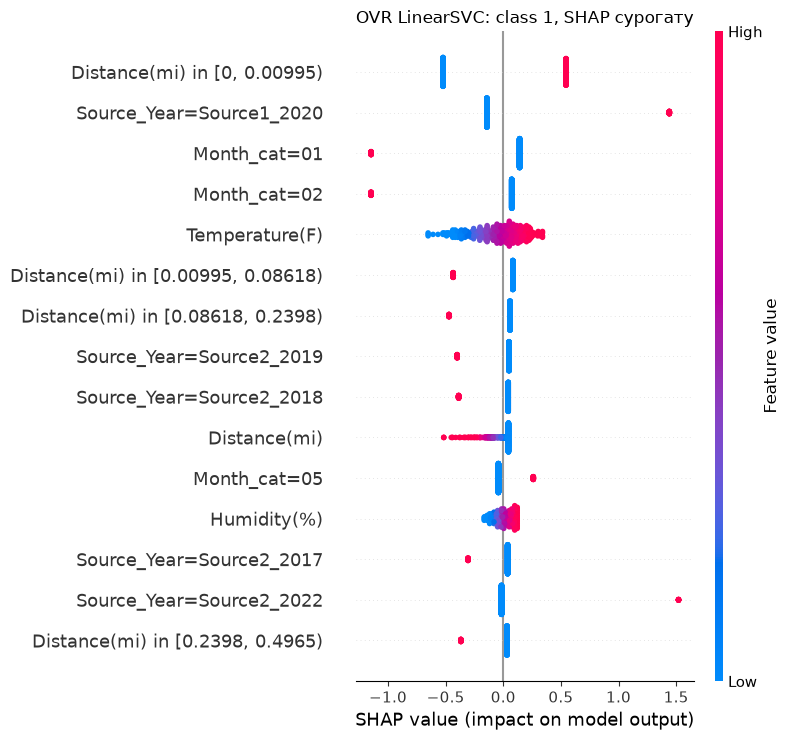

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


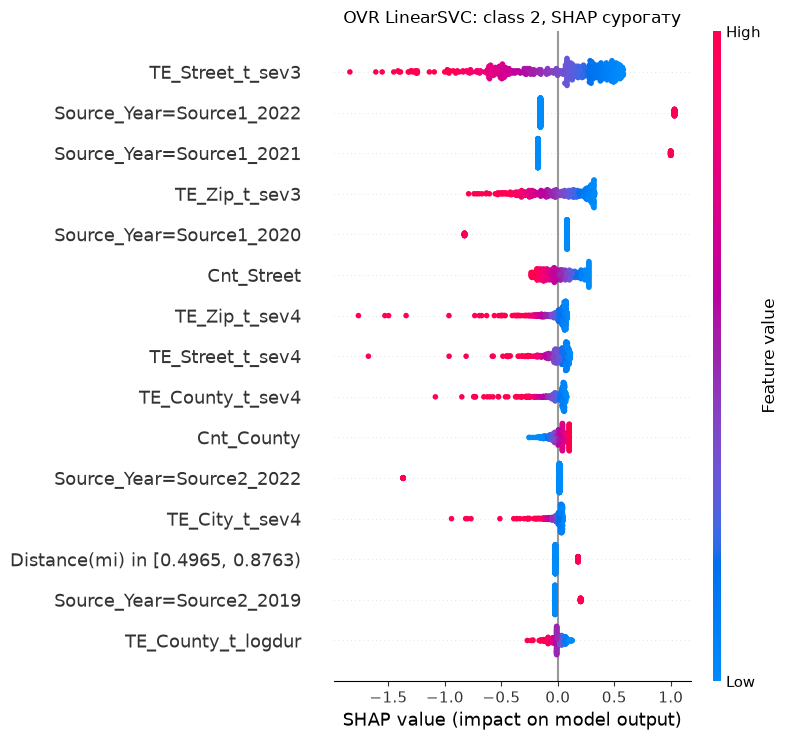

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


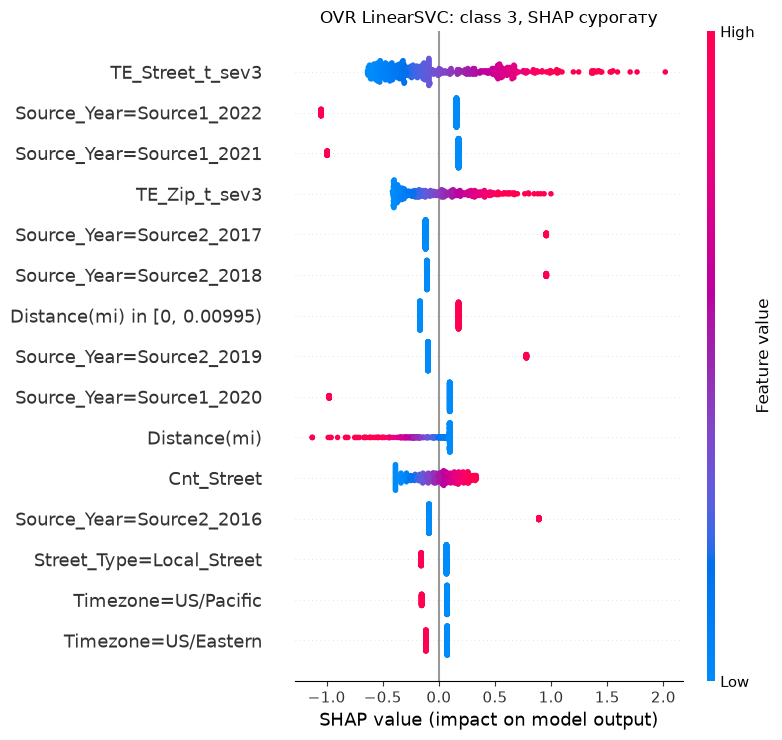

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


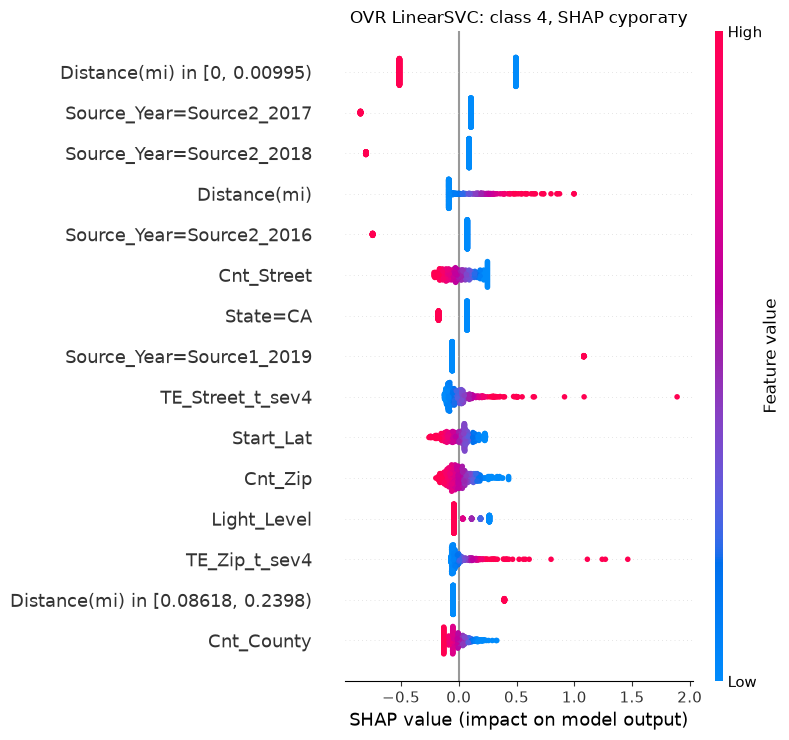

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


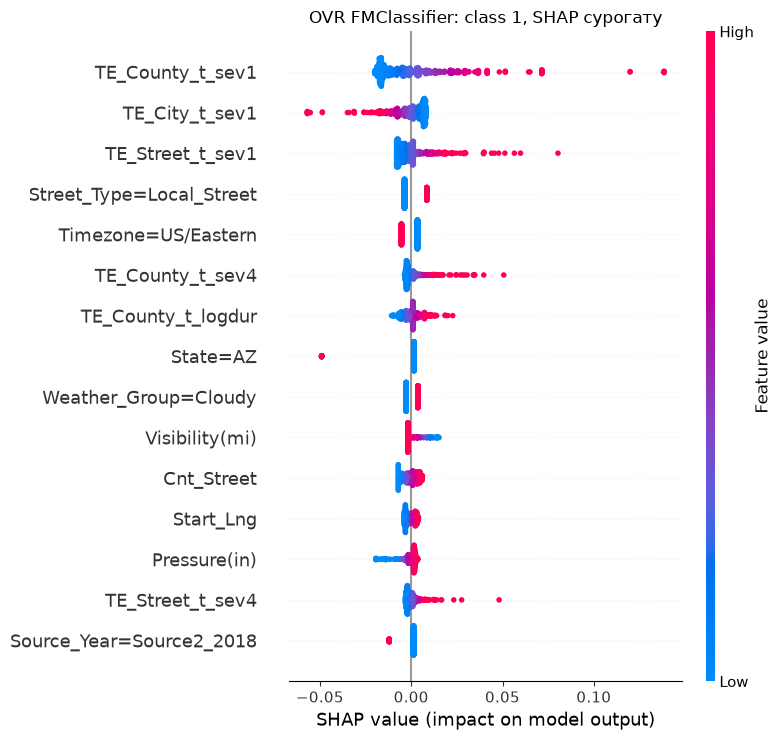

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


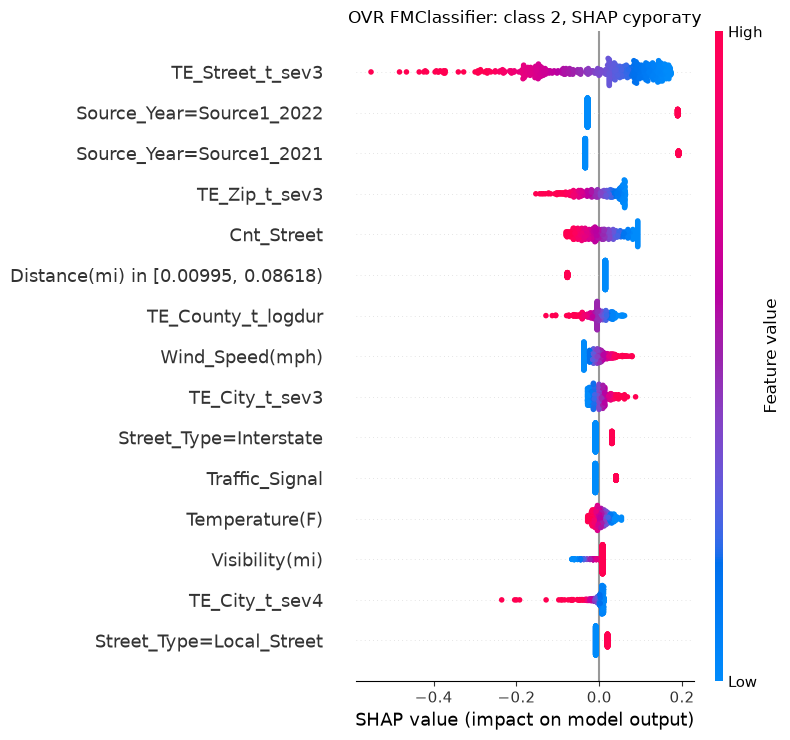

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


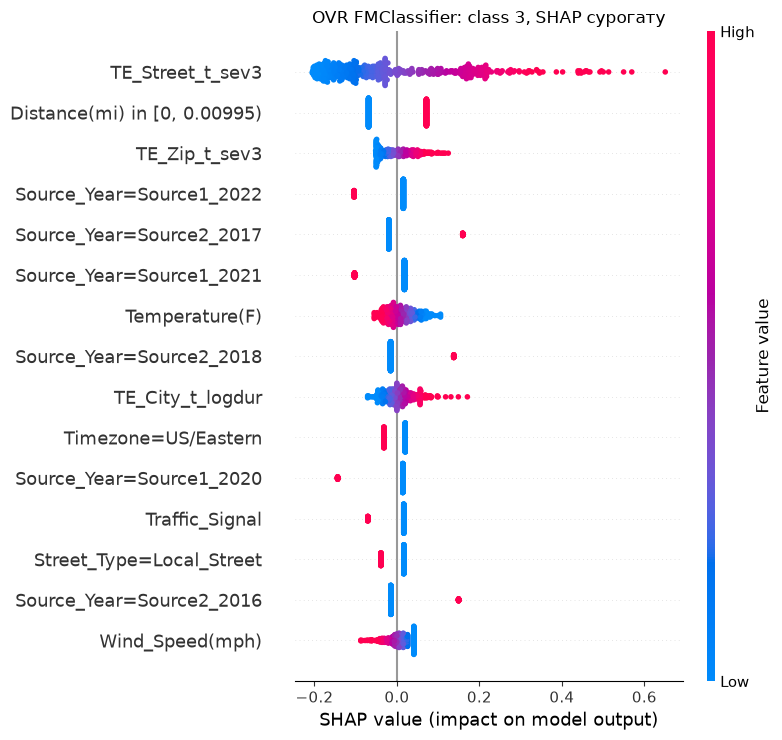

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


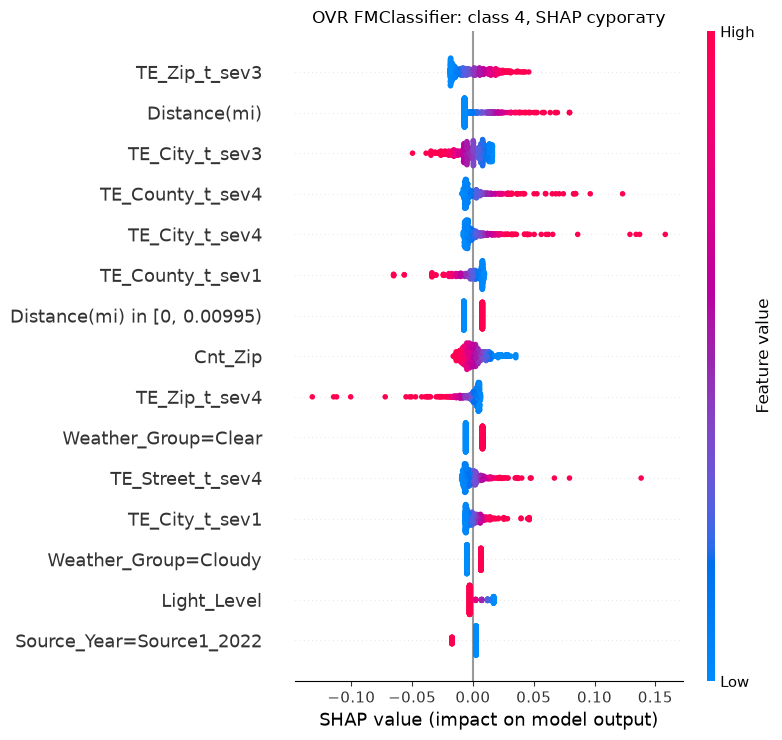

Surrogate fidelity: {'OVR LinearSVC': {'n': 2000, 'surrogate R2 by class': [0.9894987137316419, 0.9923481361691001, 0.9915739573859988, 0.9921032648097999]}, 'OVR FMClassifier': {'n': 2000, 'surrogate R2 by class': [0.1862842532615645, 0.7533912426780752, 0.6676898293380501, 0.27520205599579395]}}


In [17]:
import shap
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from pyspark.ml.linalg import Vectors

SHAP_REPORT={}
for fam,name in LEADERS.items():
    frac=min(1.,SHAP_ROWS/max(1,counts['test']))
    subset=data['test'].sampleBy('label',{float(k):frac for k in CLASSES},SEED).limit(SHAP_ROWS)
    cols=scored_frame(MODELS[name],subset).select('label','features',*[f's{k}' for k in CLASSES]).collect()
    if len(cols)<20:continue
    X=np.vstack([r['features'].toArray() for r in cols])
    S=np.array([[r[f's{k}'] for k in CLASSES] for r in cols])
    # Для відтворюваності пояснюємо найбільший score; окремий сурогат на клас.
    surrogates=[];fidelity=[]
    for k in CLASSES:
        sur=Ridge(alpha=10.).fit(X,S[:,k]);surrogates.append(sur)
        fidelity.append(float(r2_score(S[:,k],sur.predict(X))))
    background=X[:min(200,len(X))]
    for k in CLASSES:
        explainer=shap.LinearExplainer(surrogates[k],background)
        values=explainer(X[:min(500,len(X))])
        shap.summary_plot(values.values,X[:len(values.values)],feature_names=FEATURES,show=False,max_display=15)
        plt.title(f'{fam}: class {k+1}, SHAP сурогату');plt.tight_layout();plt.show()
    SHAP_REPORT[fam]={'n':len(X),'surrogate R2 by class':fidelity}
print('Surrogate fidelity:',SHAP_REPORT)

## Збереження результатів

In [19]:
for name in ("TRAIN_METRICS", "VALID_METRICS", "TEST"):
    if name in globals():
        path = OUT / f"classification_{name.lower()}.csv"
        results = globals()[name]

        if isinstance(results, pd.DataFrame):
            results.to_csv(path)
        else:
            pd.DataFrame.from_dict(results, orient="index").to_csv(path)

        print("Збережено:", path)

print("Навчені моделі в пам'яті:", list(MODELS.keys()))

import pyspark
from pathlib import Path

jars = Path(pyspark.__file__).parent / "jars"

print("Версія Hadoop:", [
    p.name for p in jars.glob("hadoop-client-api-*.jar")
])


Збережено: c:\Users\Admin\Desktop\US-Accidents-spark-project\data\models\classification_train_metrics.csv
Збережено: c:\Users\Admin\Desktop\US-Accidents-spark-project\data\models\classification_valid_metrics.csv
Збережено: c:\Users\Admin\Desktop\US-Accidents-spark-project\data\models\classification_test.csv
Навчені моделі в пам'яті: ['OVR LinearSVC base unweighted', 'OVR LinearSVC base weighted', 'OVR LinearSVC tuned unweighted', 'OVR LinearSVC tuned weighted', 'OVR FMClassifier base unweighted', 'OVR FMClassifier base weighted', 'OVR FMClassifier tuned unweighted', 'OVR FMClassifier tuned weighted']
Версія Hadoop: ['hadoop-client-api-3.5.0.jar']
